# 사이클 AE 테스트 — 데이터 받기부터 이상 판정까지

`HDI_MODEL/cycle_ae` 의 학습된 모델을 **처음부터 끝까지 손으로** 돌려 본다.

```
DB(InfluxDB) ─→ 원시 틱 ─→ 전처리기 run() ─→ 사이클 피처 ─→ + 기준선 피처 ─→ 표준화 ─→ AE ─→ 복원 오차 ─┐
                (펌프 1대)   (PumpProcessor)                 (baseline/*.json)  (meta.json)  (model.pt)        ├→ 임계값 비교 → 경보
                                                                                └──────→ 피처별 |z|/한계 ───┘    (meta.json)
```

**모델 = 파일 3개**

| 파일 | 담긴 것 | 없으면 |
|---|---|---|
| `HDI_MODEL/cycle_ae/model.py` → `CycleAE` | 신경망 **구조** (층·크기) | 가중치를 넣을 그릇이 없다 |
| `HDI_MODEL/cycle_ae/artifacts/model.pt` | 학습된 **가중치** (숫자만) | 구조만 있고 아무것도 모른다 |
| `HDI_MODEL/cycle_ae/artifacts/meta.json` | 묶음별 **표준화 통계 + 두 단계 임계값(주의·알림)**, 학습 설정 | 입력을 학습 때와 같은 척도로 못 바꾸고, 점수를 등급으로 못 바꾼다 |
| (입력 쪽) `HDI_MODEL/baseline/{펌프}.json` | 펌프별 물리 기준선 | 잔차 피처(`pump_resid`, `r_phys`)를 못 만든다 |

**테스트 데이터**

- **I7, 오늘** — DB 에서 받는다. 학습·검증·테스트 어디에도 없던 날.
  **DB 에 연결이 안 되면** 캐시의 **10/6~7** 로 대신한다 — 테스트 구간이라 기준선·학습·임계값 어디에도 안 쓴 날이고,
  I7 저항 드리프트가 재발했다가(10/6) 되돌려진(10/7 아침) 날이다
- **P7, 9/17 06:30~11:30** — 알려진 고장(유량계, 06:50~10:45). 학습에서 뺀 구간

---
## §1. 준비

In [1]:
import os, sys, io, json, time, contextlib, warnings
from collections import deque
import numpy as np
import pandas as pd
import torch
import matplotlib, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

ROOT_DIR = os.path.abspath(os.getcwd())
for p in ["HDI_MODEL", "HDI_MODEL/cycle_ae", "HDI_MODEL/baseline"]:
    sys.path.insert(0, os.path.join(ROOT_DIR, p))
sys.path.insert(0, ROOT_DIR)
matplotlib.rcParams["font.family"] = "AppleGothic"
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
warnings.simplefilter("ignore")

from new_pump_preprocessor import PumpSetup, PumpBaseline, PumpProcessor, run, add_baseline_features, load_settings
from extract_pump_cache import load_range
import model as cae                                   # HDI_MODEL/cycle_ae/model.py

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, CRITICAL = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"


PLAIN = FuncFormatter(lambda v, _: f"{v:g}")          # 로그축 눈금을 0.1, 1, 10 처럼


def style_ax(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=8)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)


S = load_settings()
ART = os.path.join(ROOT_DIR, "HDI_MODEL", "cycle_ae", "artifacts")
NB_CACHE = os.path.join(ROOT_DIR, "cache", "notebook")
os.makedirs(NB_CACHE, exist_ok=True)

---
## §2. 데이터 받기

현장 DB 를 터뜨리지 않게 **펌프 1대, 오늘 하루 치만**, 필요한 태그(펌프 7개 + 알람 4개 + 운전 1개)만 받는다.
한 번 받으면 `cache/notebook/` 에 저장해 다시 실행할 땐 DB 를 치지 않는다.
DB 연결이 안 되면 다시 두드리지 않고 캐시의 테스트 구간으로 넘어간다.

In [2]:
PUMP = "I7"
DAY = pd.Timestamp.now().strftime("%Y-%m-%d")          # 오늘
setup = PumpSetup(PUMP, S, allow_unverified=True)     # 설정 JSON → 태그 이름·점도표
tags = setup.required_tags()
print(PUMP, "필요한 태그:", tags)

FALLBACK = ("2026-10-06", "2026-10-07")             # DB 가 안 될 때: 캐시의 테스트 구간


def fetch_today():
    path = os.path.join(NB_CACHE, f"{PUMP}_{DAY}.pkl.xz")
    if os.path.exists(path):
        print("캐시에서 읽음:", path)
        return pd.read_pickle(path, compression="xz"), f"{DAY} (DB, 저장본)"
    from Log_Extractor import LogExtractor
    with contextlib.redirect_stdout(io.StringIO()):
        ex = LogExtractor(env_path=os.path.join(ROOT_DIR, ".env"))
    end = pd.Timestamp.now().floor("min").strftime("%Y-%m-%d %H:%M:%S")
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()) as buf:
        df = ex.get_data(f"{DAY} 00:00:00", end, tags)
    log = buf.getvalue()
    if "실패" in log or df is None or df.empty:
        reason = next((l.strip() for l in log.splitlines() if "실패" in l), "빈 결과")
        raise ConnectionError(reason[:160])
    df.to_pickle(path, compression="xz")
    print(f"DB 에서 받음: {DAY} 00:00 ~ {end[11:16]}  ({time.time() - t0:.1f}s) → {path}")
    return df, f"{DAY} (DB)"


try:
    raw, SOURCE = fetch_today()
except ConnectionError as e:
    print("DB 받기 실패 →", e)
    raw = load_range(PUMP, *FALLBACK)
    SOURCE = f"{FALLBACK[0]}~{FALLBACK[1]} (캐시 테스트 구간)"
    DAY = f"{FALLBACK[0]}~{FALLBACK[1][5:]}"
    print("대신 캐시의 테스트 구간을 쓴다:", SOURCE)
print(f"데이터: {SOURCE} — 틱 {len(raw):,}개, {raw.index.min()} ~ {raw.index.max()}")
raw[[setup.tags[k] for k in ("bu", "sv", "hz", "ft", "pt", "tt", "shot")]].dropna().head()

I7 필요한 태그: ['Pump_BuildUp_I7', 'g_s_SV_I7', 'Hz_Out_I7', 'Scale_Out___FT_I7', 'Scale_Out___PT_I7', 'Scale_Out___TT_I3', 'Shot_Injection_HD4_P1', 'AL_Line_Bit', 'AL_MA_Bit', 'AL_Tank_Bit', 'AL_ETC_Bit', 'Auto_Running']
캐시에서 읽음: /Users/jeonjae/Desktop/KTA/DB_Log/cache/notebook/I7_2026-10-08.pkl.xz
데이터: 2026-10-08 (DB, 저장본) — 틱 97,419개, 2026-10-08 00:00:00.325573 ~ 2026-10-08 16:04:59.667327


,Pump_BuildUp_I7,g_s_SV_I7,Hz_Out_I7,Scale_Out___FT_I7,Scale_Out___PT_I7,Scale_Out___TT_I3,Shot_Injection_HD4_P1
Time,,,,,,,
2026-10-08 00:00:00.325573,0.0,1430.0,3000.0,0.0,5.0,200.0,0.0
2026-10-08 00:00:00.830191,0.0,1430.0,3000.0,0.0,4.0,200.0,0.0
2026-10-08 00:00:01.357474,0.0,1430.0,3000.0,0.0,1.0,201.0,0.0
2026-10-08 00:00:01.879151,0.0,1430.0,3000.0,0.0,3.0,200.0,0.0
2026-10-08 00:00:02.379601,0.0,1430.0,3000.0,0.0,3.0,201.0,0.0


---
## §3. 전처리기 — 원시 틱 → 사이클 피처

`run()` 은 원시 틱을 **실시간과 같은 상태기계(`PumpProcessor`)에 시간순으로 흘린 것**이다. 사이클이 끝날 때마다 피처 한 줄이 나온다.
기준선(`baseline/I7.json`)을 넣으면 기준선 피처(`pump_resid`, `r_phys`)도 계산할 수 있다.

In [3]:
base = PumpBaseline.load(os.path.join(ROOT_DIR, "HDI_MODEL", "baseline", f"{PUMP}.json"))
t0 = time.time()
ticks, cyc, alerts = run(raw, setup, base, collect_ticks=False)
cyc = cyc[~cyc.flag_any]
cyc = add_baseline_features(cyc, base)
print(f"사이클 {len(cyc):,}개 ({time.time() - t0:.1f}s)  — 알람·정지 사이클 제외")
show = ["t_start", "SV_class", "Hz", "steady_src", "n_hz_levels", "FT", "PT", "T_C",
        "pump_resid", "r_phys", "t_self", "decel_half_sec", "release_half_sec", "ft_cv", "pt_std", "P0"]
cyc[show].head(8).round(3)

사이클 1,726개 (3.2s)  — 알람·정지 사이클 제외


,t_start,SV_class,Hz,steady_src,n_hz_levels,FT,PT,T_C,pump_resid,r_phys,t_self,decel_half_sec,release_half_sec,ft_cv,pt_std,P0
1,2026-10-08 06:51:14.218881,1210.0,4761.0,clean,1,1193.0,69.0,20.1,-0.956,1.032,1.552,1.353,0.784,0.198,2.494,31.0
2,2026-10-08 06:51:26.682801,1580.0,6354.0,shot,2,1566.0,117.0,20.0,-0.054,1.019,1.502,NaN,NaN,7.482,4.643,30.0
3,2026-10-08 06:51:39.280604,1380.0,5550.0,shot,2,1386.0,92.0,20.0,0.043,1.034,1.735,1.719,0.412,7.641,5.499,28.0
4,2026-10-08 06:52:07.459263,1420.0,5711.0,shot,2,1417.0,97.0,19.8,-0.396,1.033,1.287,1.471,0.583,9.539,1.906,26.0
5,2026-10-08 06:52:33.564857,1420.0,5711.0,clean,1,1436.0,97.0,19.7,0.909,1.033,1.430,NaN,NaN,0.949,1.932,29.0
6,2026-10-08 06:52:48.116676,1430.0,5751.0,shot,1,1430.0,98.0,19.7,-0.175,1.030,1.002,1.746,0.806,0.411,3.187,32.0
7,2026-10-08 06:53:00.560868,1310.0,5217.0,shot,1,1330.0,80.0,19.7,1.214,1.009,1.476,1.647,0.805,2.763,1.020,30.0
8,2026-10-08 06:53:13.104655,1400.0,5631.0,shot,1,1405.0,93.0,19.7,-0.174,1.017,0.992,1.502,0.362,0.000,2.160,29.0


---
## §4. 모델 불러오기 — 구조 + 가중치 + meta

In [4]:
meta = json.load(open(os.path.join(ART, "meta.json"), encoding="utf-8"))
model = cae.CycleAE(latent=meta["config"]["latent"], hidden=tuple(meta["config"]["hidden"]))   # ① 구조 (빈 그릇)
state = torch.load(os.path.join(ART, "model.pt"), map_location="cpu")                          # ② 가중치
model.load_state_dict(state)
model.eval()
print(model)
print("\n가중치 텐서:")
for k, v in state.items():
    print(f"  {k:12s} {tuple(v.shape)}")
print(f"총 파라미터 {sum(v.numel() for v in state.values()):,}개 — 파일 {os.path.getsize(os.path.join(ART, 'model.pt')) / 1024:.0f} KB")
print(f"\n복원 피처 {meta['features']}\n조건 {meta['conds']}\n학습 {meta['created']}, 묶음 {len(meta['stats'])}개")

CycleAE(
  (enc): Sequential(
    (0): Linear(in_features=14, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=4, bias=True)
  )
  (dec): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=8, bias=True)
  )
)

가중치 텐서:
  enc.0.weight (32, 14)
  enc.0.bias   (32,)
  enc.2.weight (16, 32)
  enc.2.bias   (16,)
  enc.4.weight (4, 16)
  enc.4.bias   (4,)
  dec.0.weight (16, 10)
  dec.0.bias   (16,)
  dec.2.weight (32, 16)
  dec.2.bias   (32,)
  dec.4.weight (8, 32)
  dec.4.bias   (8,)
총 파라미터 2,060개 — 파일 12 KB

복원 피처 ['pump_resid', 'r_phys', 't_self', 'decel_half_sec', 'release_half_sec', 'ft_cv', 'pt_std', 'P0']
조건 ['mu_rel_z', 'hz_rel', 'dhz_rel', 'is_iso', 'is_shot', 'is_multi']
학습 2026-10-08T16:21:54, 묶음 37개


In [5]:
# ③ meta.json — 이 펌프 묶음들의 표준화 통계와 임계값
rows = []
for k, s in meta["stats"].items():
    if k.startswith(PUMP + "|"):
        t = meta["thresholds"][k]
        rows.append({"묶음": k, "학습 사이클": s["n_fit"], "대표 Hz": round(s["hz_med"]),
                     "pump_resid 중앙/척도": f"{s['med']['pump_resid']:+.2f} / {s['scale']['pump_resid']:.2f}",
                     "r_phys 중앙/척도": f"{s['med']['r_phys']:.3f} / {s['scale']['r_phys']:.4f}",
                     "주의 AE/수준": f"{t['warn']['cycle']:.2f} / {t['warn']['zmax']:.2f}",
                     "알림 AE/수준": f"{t['alert']['cycle']:.2f} / {t['alert']['zmax']:.2f}",
                     "창 주의 AE/수준": f"{t['warn']['roll']:.2f} / {t['warn']['zmax_roll']:.2f}",
                     "창 알림 AE/수준": f"{t['alert']['roll']:.2f} / {t['alert']['zmax_roll']:.2f}"})
pd.DataFrame(rows).set_index("묶음")

,학습 사이클,대표 Hz,pump_resid 중앙/척도,r_phys 중앙/척도,주의 AE/수준,알림 AE/수준,창 주의 AE/수준,창 알림 AE/수준
묶음,,,,,,,,
I7|clean|multi,3691,5952,+0.65 / 0.49,0.999 / 0.0074,1.80 / 1.69,2.81 / 3.77,0.57 / 1.35,8.05 / 4.44
I7|clean|single,4387,5336,+0.37 / 0.41,1.003 / 0.0051,4.31 / 1.32,7.32 / 1.88,0.81 / 0.91,2.08 / 5.01
I7|shot|multi,7206,5550,+0.20 / 0.62,1.001 / 0.0083,2.51 / 1.08,4.92 / 1.55,0.55 / 0.96,2.13 / 4.91
I7|shot|single,3740,5057,+0.28 / 0.53,0.998 / 0.0103,1.92 / 1.78,2.80 / 2.35,0.69 / 0.90,4.70 / 4.67


---
## §5. 이상 판정은 어디서 하나 — 한 사이클을 손으로

`CycleScorer.score()` 가 안에서 하는 일을 그대로 풀어 쓴다. **판정은 ⑤ 한 줄** — 점수가 묶음별 임계값을 넘는지.
나머지는 그 점수를 만드는 과정이다.

In [6]:
def by_hand(row):
    """사이클 한 줄 → 단계별 값."""
    k = cae.group_key(PUMP, row["steady_src"], row["n_hz_levels"])
    s = meta["stats"][k]
    F = meta["features"]
    # ① 표준화: (값 − 묶음 중앙값) / 묶음 척도  — 펌프·레시피 차이를 지운다
    z = np.array([(row[f] - s["med"][f]) / s["scale"][f] for f in F], float)
    obs = np.isfinite(z)
    x = np.clip(np.where(obs, z, 0.0), -cae.CLIP, cae.CLIP).astype(np.float32)
    # ② 조건
    c = np.array([np.clip((row["mu_rel"] - s["mu_med"]) / s["mu_scale"], -cae.CLIP, cae.CLIP),
                  row["Hz"] / s["hz_med"] - 1.0,
                  np.clip(np.nan_to_num(row["dHz_prev"] / row["Hz"]), -1, 1),
                  float(s["material"] == "ISO"), float(s["steady_src"] == "shot"), float(s["multi"])], np.float32)
    # ③ AE 복원
    with torch.no_grad():
        xhat = model(torch.from_numpy(x[None]), torch.from_numpy(c[None])).numpy()[0]
    err = np.where(obs, (xhat - x) ** 2, np.nan)
    score = np.nanmean(err)                                     # 패턴 점수
    # ④ 수준 점수: 피처별 |z| / 그 피처의 정상 한계
    zl = np.abs(z) / np.array([s["zq"][f] for f in F])
    zmax = np.nanmax(zl)
    # ⑤ 판정 — 여기가 이상탐지
    thr = meta["thresholds"][k]
    alarm_ae, alarm_z = score > thr["warn"]["cycle"], zmax > thr["warn"]["zmax"]            # 주의
    alert = score > thr["alert"]["cycle"] or zmax > thr["alert"]["zmax"]                   # 알림
    detail = pd.DataFrame({"원값": [row[f] for f in F], "표준화 z": z, "복원 x̂": xhat, "복원 오차²": err, "|z|/한계": zl}, index=F)
    return k, detail, score, zmax, thr, alarm_ae, alarm_z, alert


# 경보가 안 난 사이클 하나와, 점수가 가장 높은 사이클 하나
sc = cae.CycleScorer.load(ART)
scored = sc.score(cyc.assign(pump=PUMP, material=base.material))
calm = scored[~scored.alarm & scored.in_scope]
for title, i in [("경보 없는 사이클 (그중 점수 중앙값)", (calm.score - calm.score.median()).abs().idxmin()),
                 ("점수가 가장 높은 사이클", scored.score.idxmax())]:
    row = cyc.loc[i]
    k, detail, score, zmax, thr, a1, a2, al = by_hand(row)
    print(f"■ {title} — {row.t_start:%m-%d %H:%M:%S}  묶음 {k}")
    print(f"   패턴 점수 {score:.3f}  (주의 {thr['warn']['cycle']:.3f} / 알림 {thr['alert']['cycle']:.3f})")
    print(f"   수준 점수 {zmax:.3f}  (주의 {thr['warn']['zmax']:.3f} / 알림 {thr['alert']['zmax']:.3f})")
    print(f"   사이클 등급: {'★ 알림' if al else ('주의' if (a1 or a2) else '정상')}")
    display(detail.round(3))

■ 경보 없는 사이클 (그중 점수 중앙값) — 10-08 08:35:57  묶음 I7|shot|multi
   패턴 점수 0.205  (주의 2.506 / 알림 4.918)
   수준 점수 0.349  (주의 1.082 / 알림 1.553)
   사이클 등급: 정상


,원값,표준화 z,복원 x̂,복원 오차²,|z|/한계
pump_resid,-0.656,-1.385,-0.960,0.181,0.062
r_phys,1.012,1.245,1.415,0.029,0.217
t_self,1.561,0.267,0.429,0.026,0.021
decel_half_sec,1.439,0.136,0.134,0.000,0.045
release_half_sec,0.389,-1.046,-0.349,0.486,0.349
ft_cv,8.517,-0.241,-0.918,0.459,0.049
pt_std,3.304,0.135,0.799,0.441,0.025
P0,27.000,-0.674,-0.534,0.020,0.225


■ 점수가 가장 높은 사이클 — 10-08 14:16:50  묶음 I7|clean|single
   패턴 점수 11.792  (주의 4.309 / 알림 7.318)
   수준 점수 1.328  (주의 1.321 / 알림 1.878)
   사이클 등급: ★ 알림


,원값,표준화 z,복원 x̂,복원 오차²,|z|/한계
pump_resid,-1.765,-5.219,-5.869,0.421000,1.150
r_phys,0.943,-11.805,-4.208,57.703999,1.328
t_self,1.400,-0.367,0.145,0.262000,0.115
decel_half_sec,1.440,0.149,0.564,0.172000,0.050
release_half_sec,0.381,-1.490,0.574,4.258000,0.465
ft_cv,0.514,-0.431,1.239,2.789000,0.068
pt_std,0.943,-1.061,1.888,8.696000,0.333
P0,28.000,0.000,-4.476,20.031000,0.000


In [7]:
# 손 계산 == 채점기 (CycleScorer.score) 인가
chk = []
for i in scored.sample(min(300, len(scored)), random_state=0).index:
    k, detail, score, zmax, thr, a1, a2, al = by_hand(cyc.loc[i])
    lvl = "알림" if al else ("주의" if (a1 or a2) else "정상")
    chk.append((score, scored.loc[i, "score"], zmax, scored.loc[i, "zmax"], lvl, scored.loc[i, "level"]))
chk = np.array(chk, dtype=object)
d = np.abs(chk[:, 0].astype(float) - chk[:, 1].astype(float))
print(f"점수 차이 최대 {d.max():.1e} (float32 계산 오차 수준) — 일치:", np.allclose(chk[:, 0].astype(float), chk[:, 1].astype(float), rtol=1e-4, atol=1e-5),
      "| 수준 일치:", np.allclose(chk[:, 2].astype(float), chk[:, 3].astype(float), rtol=1e-5),
      "| 등급 일치:", (chk[:, 4] == chk[:, 5]).all(), f"({len(chk)}개 비교)")

점수 차이 최대 7.2e-06 (float32 계산 오차 수준) — 일치: True | 수준 일치: True | 등급 일치: True (300개 비교)


**정리 — 이상탐지는 세 군데에서 결정된다**

| 단계 | 하는 일 | 코드 |
|---|---|---|
| 기준선 잔차 | "이 Hz·온도면 이만큼 나와야 한다" 대비 얼마나 벗어났나 | `add_baseline_features` (전처리기) |
| 점수 | 패턴(AE 복원 오차) + 수준(피처별 \|z\|/한계) | `model.prepare`, `model.errors`, `model.zlevel` |
| **판정 — 사이클** | 점수 > 묶음별 임계값 → 등급 (정상/주의/알림) | `model.add_levels` → `level`, `alarm`(주의 이상), `alert` |
| **판정 — 사람에게 알림** | 같은 묶음 최근 10사이클 중앙값 > 창 임계값 → 펌프 등급. **알림으로 새로 올라간 순간 한 번** | `model.WindowTracker.update` → `notify` |

AE 는 "평소 피처들이 어떻게 같이 움직이는지" 를 배운 것이고, 그걸로 복원이 안 되면 점수가 오른다.
경보가 울리면 `top_feature` 로 **어느 피처가 어느 쪽으로** 벗어났는지 같이 나온다.

---
## §6. 결과 — 처음 보는 날 두 가지

- **6-1. §2 에서 받은 데이터** (DB 가 되면 오늘, 안 되면 10/6~7)
- **6-2. 10/6~7 캐시** — 테스트 구간(기준선·학습·임계값에 안 쓴 날). I7 저항 드리프트가 재발했다가 되돌려진 이틀

정상인 날이면 경보율이 임계값을 정한 비율(사이클 약 1%) 근처에 있어야 하고, 이상이 있는 날이면 그 시간대에 몰려야 한다.

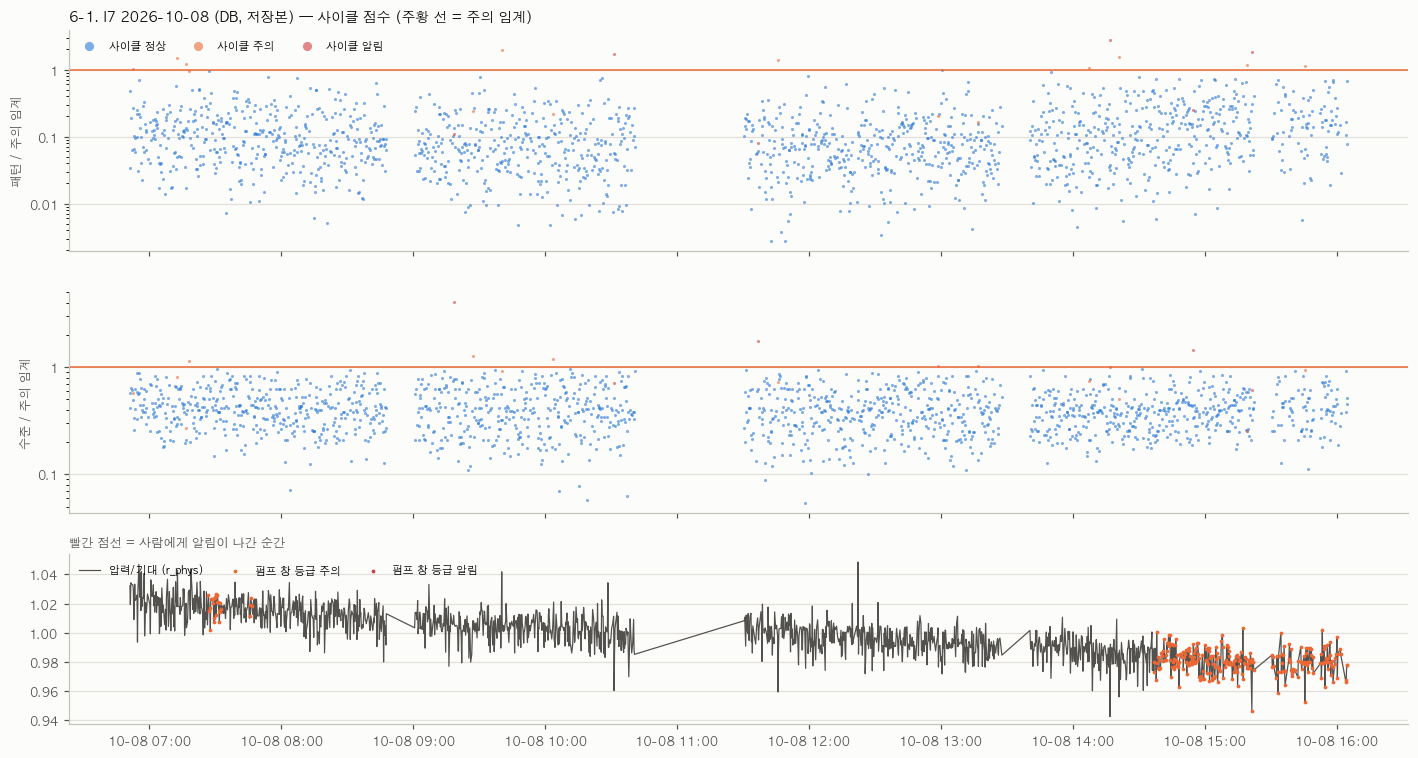

[2026-10-08 (DB, 저장본)] 사이클 1,726 | 범위 안 100.0% | 사이클 주의 이상 1.2% (알림 0.3%) | 펌프 창 주의 이상 16.8% | 사람에게 알림 0회
  경보 이유: {('r_phys', '낮음'): 7, ('pump_resid', '높음'): 6, ('r_phys', '높음'): 3, ('release_half_sec', '높음'): 3, ('P0', '높음'): 1}


,주의,알림,창주의,창알림,r_phys,pump_resid,P0,FT_SV
t_start,,,,,,,,
2026-10-08 06:00:00,0.009,0.000,0.063,0.0,1.015,0.254,28.0,1.004
2026-10-08 09:00:00,0.015,0.006,0.000,0.0,1.003,0.289,28.0,1.007
2026-10-08 12:00:00,0.009,0.003,0.135,0.0,0.991,0.385,28.0,1.009
2026-10-08 15:00:00,0.017,0.006,1.000,0.0,0.980,0.381,27.0,1.009


In [8]:
ROLL = meta["roll"]
thr = meta["thresholds"]
LV_COLOR = {"정상": BLUE, "주의": ORANGE, "알림": CRITICAL}


def score_cycles(cy, bs):
    s = sc.score(cy.assign(pump=PUMP, material=bs.material))
    return cae.window_levels(s, meta).sort_values("t_start").reset_index(drop=True)   # 실시간과 같은 WindowTracker


def plot_scores(s, title):
    fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True, facecolor=SURFACE, gridspec_kw={"height_ratios": [1.3, 1.3, 1]})
    ok = s.in_scope
    for ax, col, key, lab in [(axes[0], "score", "cycle", "패턴 / 주의 임계"), (axes[1], "zmax", "zmax", "수준 / 주의 임계")]:
        r = s[col] / s.group.map({k: v["warn"][key] for k, v in thr.items()})
        for lv, c in LV_COLOR.items():
            m = ok & (s.level == lv)
            ax.scatter(s.t_start[m], r[m], s=4, color=c, lw=0, alpha=0.6, label=f"사이클 {lv}")
        ax.axhline(1, color=ORANGE, lw=1)
        ax.set_yscale("log"); ax.yaxis.set_major_formatter(PLAIN); style_ax(ax)
        ax.set_ylabel(lab, color=INK2, fontsize=8)
    axes[0].legend(fontsize=7, frameon=False, loc="upper left", markerscale=3, ncol=3)
    axes[0].set_title(title + " — 사이클 점수 (주황 선 = 주의 임계)", loc="left", color=INK, fontsize=9, fontweight="bold")
    ax = axes[2]
    ax.plot(s.t_start, s.r_phys, color=INK2, lw=0.8, label="압력/기대 (r_phys)")
    for lv in ("주의", "알림"):
        m = s.pump_level == lv
        ax.scatter(s.t_start[m], s.r_phys[m], s=6, color=LV_COLOR[lv], lw=0, label=f"펌프 창 등급 {lv}", zorder=3)
    for t in s[s.notify].t_start:
        ax.axvline(t, color=CRITICAL, lw=1, ls="--")
    style_ax(ax); ax.legend(fontsize=7, frameon=False, loc="upper left", ncol=3)
    ax.set_title("빨간 점선 = 사람에게 알림이 나간 순간", loc="left", color=INK2, fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M"))
    fig.tight_layout(); plt.show()


def summary(s, label):
    lv = s.level.value_counts(normalize=True) * 100
    print(f"[{label}] 사이클 {len(s):,} | 범위 안 {s.in_scope.mean() * 100:.1f}% | 사이클 주의 이상 {s.alarm.mean() * 100:.1f}% "
          f"(알림 {lv.get('알림', 0):.1f}%) | 펌프 창 주의 이상 {(s.pump_level != '정상').mean() * 100:.1f}% | "
          f"사람에게 알림 {int(s.notify.sum())}회")
    for _, r in s[s.notify].iterrows():
        print(f"  🔔 {r.t_start:%m-%d %H:%M}  이유: {r.notify_reason}")
    print("  경보 이유:", s[s.alarm].groupby(["top_feature", "top_dir"]).size().sort_values(ascending=False).head(5).to_dict())
    x = s.assign(주의=s.level != "정상", 알림=s.level == "알림", 창주의=s.pump_level != "정상", 창알림=s.pump_level == "알림")
    return x.set_index("t_start").resample("3h").agg({"주의": "mean", "알림": "mean", "창주의": "mean", "창알림": "mean",
                                                      "r_phys": "median", "pump_resid": "median", "P0": "median",
                                                      "FT_SV": "median"}).dropna().round(3)


S1 = score_cycles(cyc, base)
plot_scores(S1, f"6-1. {PUMP} {SOURCE}")
summary(S1, SOURCE)

### 6-2. 10/6~7 — 저항 드리프트 재발

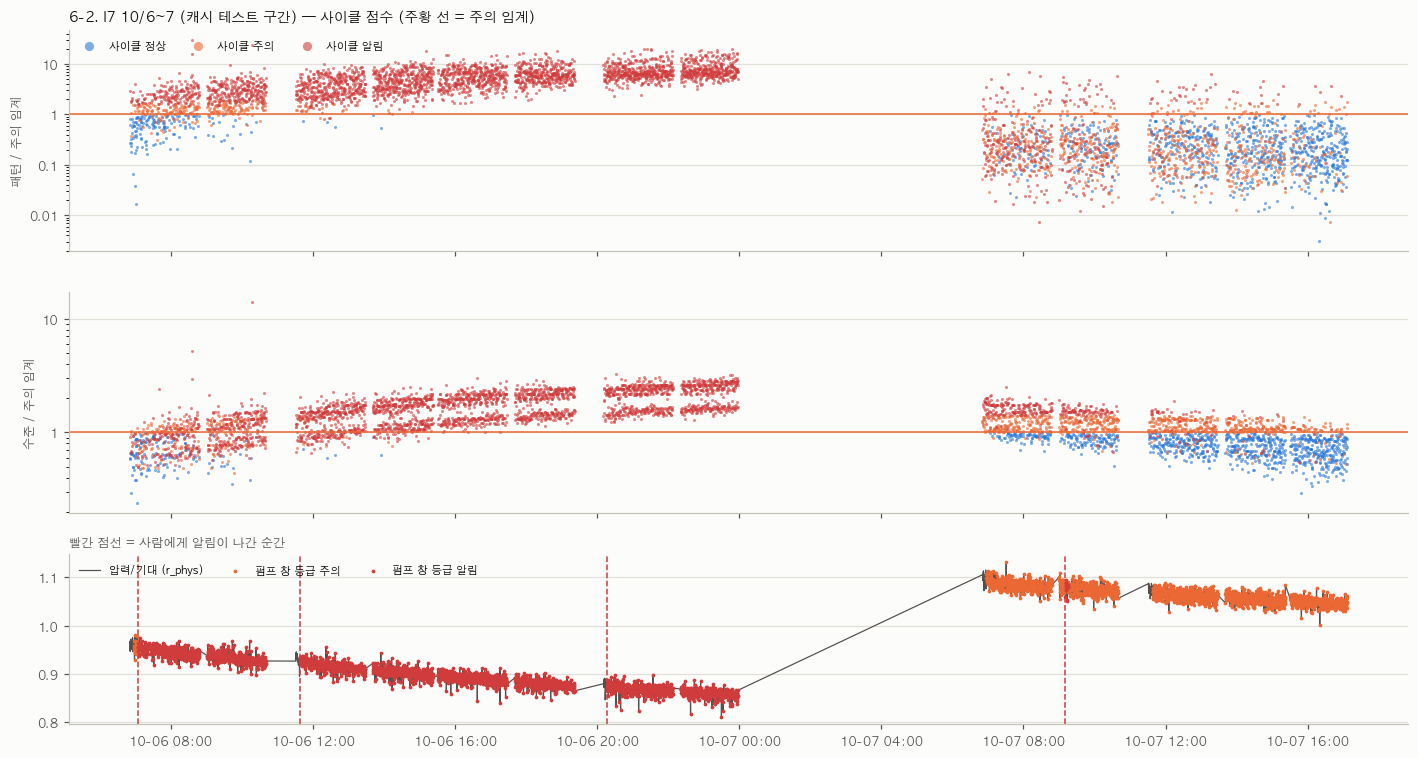

[10/6~7] 사이클 5,449 | 범위 안 100.0% | 사이클 주의 이상 79.0% (알림 59.5%) | 펌프 창 주의 이상 97.8% | 사람에게 알림 4회
  🔔 10-06 07:03  이유: r_phys 낮음
  🔔 10-06 11:38  이유: r_phys 낮음
  🔔 10-06 20:16  이유: r_phys 낮음
  🔔 10-07 09:10  이유: r_phys 높음
  경보 이유: {('r_phys', '낮음'): 3102, ('r_phys', '높음'): 1040, ('ft_cv', '높음'): 47, ('P0', '높음'): 38, ('P0', '낮음'): 22}


,주의,알림,창주의,창알림,r_phys,pump_resid,P0,FT_SV
t_start,,,,,,,,
2026-10-06 06:00:00,0.691,0.381,0.948,0.887,0.946,0.088,26.0,1.009
2026-10-06 09:00:00,0.962,0.710,0.954,0.954,0.932,0.050,26.0,1.010
2026-10-06 12:00:00,0.994,0.977,1.000,1.000,0.911,0.077,25.0,1.012
2026-10-06 15:00:00,1.000,1.000,1.000,1.000,0.891,-0.013,25.0,1.016
2026-10-06 18:00:00,1.000,1.000,0.965,0.965,0.877,-0.050,24.0,1.017
2026-10-06 21:00:00,1.000,1.000,1.000,1.000,0.864,-0.141,24.0,1.018
2026-10-07 06:00:00,0.822,0.423,0.944,0.000,1.087,0.408,31.0,1.000
2026-10-07 09:00:00,0.678,0.247,0.944,0.029,1.075,0.389,30.0,1.000
2026-10-07 12:00:00,0.460,0.050,1.000,0.000,1.059,0.269,30.0,1.000


In [9]:
raw2 = load_range(PUMP, "2026-10-06", "2026-10-07")
_, cy2, _ = run(raw2, setup, base, collect_ticks=False)
cy2 = add_baseline_features(cy2[~cy2.flag_any], base)
S2 = score_cycles(cy2, base)
plot_scores(S2, f"6-2. {PUMP} 10/6~7 (캐시 테스트 구간)")
summary(S2, "10/6~7")

**읽기**

- **6-1**: 경보율을 calib(정상 건강일) 경보율 약 1% 와 비교한다 — 비슷하면 그날은 정상이고, 특정 시간대에 몰려 있으면 그 시간대를 본다.
  10/8 로 돌렸을 때: 사이클 주의 1.2%(알림 0.3%), 사람에게 간 알림 0회 — 정상 수준. 다만 압력/기대가 06시 1.015 → 15시 0.98 로
  내려가며 **15시대부터 펌프 창 등급이 "주의"** 로 올라 있다 — 10/6 과 같은 드리프트가 다시 시작되는 모양일 수 있다(알림 단계는 아직)
- **6-2, 10/6**: 압력/기대(`r_phys`)가 0.95 → 0.86 으로 하루 종일 서서히 빠진다 — 9/23 전에 반복되던 I7 저항 드리프트의 재발.
  처음엔 사이클 절반, 오후부터는 전부 경보. 이유는 거의 다 "r_phys 낮음"
- **6-2, 10/7 아침**: 1.09 로 한 번에 올라갔다가(다시 조인 것으로 추정 — 평소보다 **더** 조였다) 1.05 까지 내려오는 중. 이번엔 "r_phys 높음"
- 모델이 처음 본 이상을 "어느 피처가 어느 쪽으로" 까지 맞게 짚었다

---
## §7. 실시간처럼 — 틱을 하나씩 흘리며 판정

현장에서는 `PumpProcessor.update(now, row)` 를 틱마다 부르고, 사이클이 끝나는 순간 나오는 `cycle` 을 바로 채점(`score_one`)하고,
그 점수를 `WindowTracker.update` 에 넣어 **펌프 등급**과 **알림 여부(`notify`)** 를 받는다.

알려진 고장 **P7 유량계** 로 — 고장 전날 밤(9/16 21:30)부터 흘린다.
- 9/16 22시부터 전조: 펌프 잔차 0 → −1%, 유량 흔들림(ft_cv) 2배 — 유량계가 약 1% 낮게 읽고 흔들리기 시작
- 9/17 06:50 재가동 첫 사이클부터 FT 가 서서히 줄어 5분 만에 FT/SV 0.55, 이후 4시간 0 근처

In [10]:
def live(pump, start, end):
    stp = PumpSetup(pump, S, allow_unverified=True)
    bs = PumpBaseline.load(os.path.join(ROOT_DIR, "HDI_MODEL", "baseline", f"{pump}.json"))
    rw = load_range(pump, start[:10], end[:10])
    rw = rw[(rw.index >= start) & (rw.index < end)]
    proc = PumpProcessor(stp, bs)                 # 전처리기 (틱 → 사이클)
    win = cae.WindowTracker(meta)                 # 창 판정 (사이클 → 펌프 등급·알림)
    out, t_inf = [], []
    for ts, row in zip(rw.index, rw.to_dict("records")):
        o = proc.update(ts, row)                  # ← 틱 하나
        cy = o["cycle"]
        if cy is None or cy["flag_any"] or not (cy["FT"] > 0):
            continue
        t1 = time.perf_counter()
        r = sc.score_one(add_baseline_features(cy, bs), pump)                       # ← 사이클 끝: 채점
        w = win.update(pump, r["group"], r["score"], r["zmax"], t=cy["t_start"],
                       reason=f"{r['top_feature']} {r['top_dir']}", level=r["level"])   # ← 창 판정
        t_inf.append(time.perf_counter() - t1)
        out.append({"t": ts, "start": cy["t_start"], "group": r["group"], "score": r["score"], "zmax": r["zmax"],
                    "level": r["level"], "pump_level": w["pump_level"], "notify": w["notify"],
                    "why": f"{r['top_feature']} {r['top_dir']}", "pump_resid": cy["pump_resid"], "FT_SV": cy["FT_SV"]})
        if w["notify"]:
            print(f"🔔 {ts:%m-%d %H:%M:%S}  {pump} 알림 — 이유(최근 10사이클 최빈): {w['reason']}, "
                  f"묶음 {r['group']} 창 중앙값 점수 {w['score_med']:.2f} / 수준 {w['zmax_med']:.2f}")
    print(f"... 채점+창 판정 1회 평균 {np.mean(t_inf) * 1000:.1f} ms, 사이클 {len(out):,}개")
    return pd.DataFrame(out)


lv = live("P7", "2026-09-16 21:30", "2026-09-17 11:30")
x = lv.assign(주의=lv.level != "정상", 알림=lv.level == "알림", 펌프알림=lv.pump_level == "알림")
x.set_index("t").resample("1h").agg({"주의": "mean", "알림": "mean", "펌프알림": "mean", "notify": "sum",
                                     "pump_resid": "median", "FT_SV": "median"}).dropna().round(3)

🔔 09-16 22:26:10  P7 알림 — 이유(최근 10사이클 최빈): pump_resid 낮음, 묶음 P7|shot|multi 창 중앙값 점수 1.16 / 수준 0.91
🔔 09-17 06:56:43  P7 알림 — 이유(최근 10사이클 최빈): ft_cv 높음, 묶음 P7|clean|single 창 중앙값 점수 3.06 / 수준 3.06
... 채점+창 판정 1회 평균 3.1 ms, 사이클 1,378개


,주의,알림,펌프알림,notify,pump_resid,FT_SV
t,,,,,,
2026-09-16 21:00:00,0.025,0.008,0.000,0,-0.068,1.005
2026-09-16 22:00:00,0.119,0.052,0.361,1,-0.542,1.000
2026-09-16 23:00:00,0.351,0.182,0.889,0,-1.615,0.992
2026-09-17 06:00:00,0.882,0.735,0.353,1,-18.260,0.823
2026-09-17 07:00:00,1.000,1.000,1.000,0,-97.974,0.020
2026-09-17 08:00:00,1.000,1.000,1.000,0,-96.936,0.031
2026-09-17 09:00:00,1.000,1.000,1.000,0,-99.435,0.006
2026-09-17 10:00:00,1.000,1.000,1.000,0,-98.448,0.016


---
## §8. 임계값 — 어떻게 정했고, 어떻게 고르나

### 지금 값

`train.py` 가 묶음마다 **두 단계**로 정했다 (`THR_Q = {"warn": 0.995, "alert": 0.999}`):

| | 주의 (warn) | 알림 (alert) |
|---|---|---|
| 사이클 임계값 | 학습에 **안 쓴** 건강일(`calib`) 점수의 상위 0.5% | 상위 0.1% |
| 창 임계값 | 학습+calib 건강일의 10사이클 중앙값 상위 0.5% | 상위 0.1% |
| 쓰임 | 대시보드·기록 | 펌프 창 등급이 알림으로 올라가는 순간 **사람에게 한 번** |

"정상인데 울리는 비율" 을 정한 것이다. 아래는 I7 묶음 하나의 calib 점수 분포와 두 임계값.

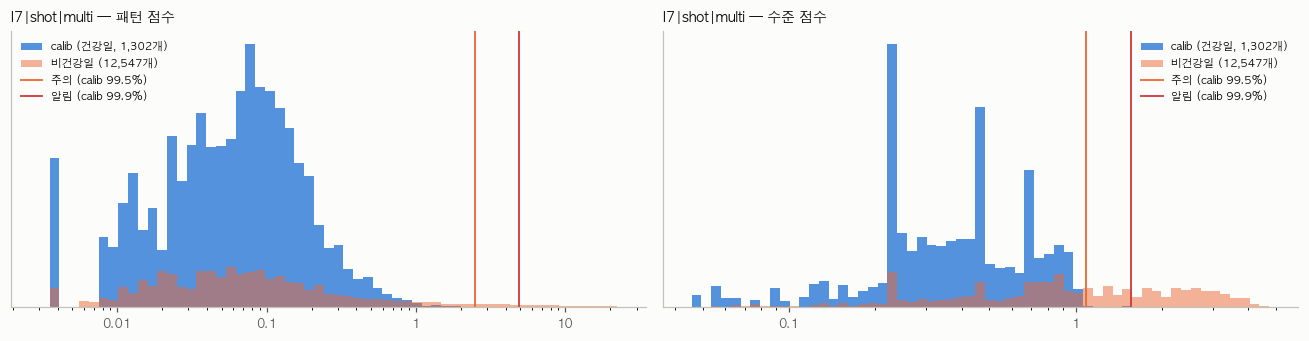

In [11]:
SC = pd.read_pickle(os.path.join(ROOT_DIR, "cache", "pump_dataset", "scores.pkl.xz"), compression="xz")
k = f"{PUMP}|shot|multi"
g = SC[(SC.group == k)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), facecolor=SURFACE)
for ax, col, key, ttl in [(axes[0], "score", "cycle", "패턴 점수"), (axes[1], "zmax", "zmax", "수준 점수")]:
    v = g[g.role == "calib"][col].dropna()
    bins = np.logspace(np.log10(max(v.min(), 1e-3)), np.log10(v.max() * 3), 60)
    ax.hist(v, bins=bins, color=BLUE, alpha=0.8, density=True, label=f"calib (건강일, {len(v):,}개)")
    e = g[(g.role == "eval") & (g.split != "test") & ~g.excluded][col].dropna()
    ax.hist(e, bins=bins, color=ORANGE, alpha=0.5, density=True, label=f"비건강일 ({len(e):,}개)")
    ax.set_yticks([])                                  # 개수가 10배 달라 비율(밀도)로 겹쳐 본다
    ax.axvline(meta["thresholds"][k]["warn"][key], color=ORANGE, lw=1.2, label="주의 (calib 99.5%)")
    ax.axvline(meta["thresholds"][k]["alert"][key], color=CRITICAL, lw=1.2, label="알림 (calib 99.9%)")
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(PLAIN); style_ax(ax); ax.legend(fontsize=7, frameon=False)
    ax.set_title(f"{k} — {ttl}", loc="left", color=INK, fontsize=9, fontweight="bold")
fig.tight_layout(); plt.show()

### 분위를 바꾸면 — 오경보 vs 검출

**사이클 단위 0.5% 는 현장에선 많다.** P7 은 하루 3,000사이클이라 정상이어도 하루 15번 울린다.
그래서 알림은 **창 경보가 새로 켜진 횟수(에피소드)** 로 세고, 사이클 경보는 기록용으로 두는 게 맞다.
분위를 0.99 ~ 0.9995 로 바꿔 가며 **정상 날의 펌프당 하루 경보 횟수**와 **알려진 이벤트 검출률**을 본다.

In [12]:
EVENTS = {"P7 유량계 고장": "P7", "I1 노즐 저항 감소 (FT/SV 1.09)": "I1", "I1 노즐 저항 증가 (K 7.8)": "I1",
          "P2 배관 저항 +7%": "P2", "I7 저항 드리프트 재발 (테스트)": "I7"}
SC = SC.sort_values(["group", "t_start"]).reset_index(drop=True)
normal = SC.role.isin(["fit", "calib"]) & SC.in_scope


def sweep(q):
    th = {}
    for k, n in SC[normal].groupby("group"):
        c = n[n.role == "calib"]
        src = c if len(c) >= meta["min_calib"] else n
        th[k] = (src.score.quantile(q), src.zmax.quantile(q), n.score_roll.quantile(q), n.zmax_roll.quantile(q))
    m = lambda j: SC.group.map({k: v[j] for k, v in th.items()})  # noqa: E731
    a = (SC.score > m(0)) | (SC.zmax > m(1))
    w = (SC.score_roll > m(2)) | (SC.zmax_roll > m(3))
    onset = w & ~w.groupby(SC.group).shift(1, fill_value=False)          # 창 경보가 새로 켜진 사이클
    cal = SC.role == "calib"
    pump_days = SC[cal].groupby(["pump", "day"]).ngroups
    r = {"분위": q, "calib 사이클 경보%": a[cal].mean() * 100,
         "정상 날 펌프당 하루 사이클 경보": a[cal].sum() / pump_days,
         "정상 날 펌프당 하루 창 에피소드": onset[cal].sum() / pump_days}
    for ev in EVENTS:
        e = SC.event == ev
        r[ev[:12] + " 창%"] = w[e & SC.in_scope].mean() * 100
    return r


SW = pd.DataFrame([sweep(q) for q in [0.99, 0.995, 0.999, 0.9995]]).set_index("분위")
SW.round(2)

,calib 사이클 경보%,정상 날 펌프당 하루 사이클 경보,정상 날 펌프당 하루 창 에피소드,P7 유량계 고장 창%,I1 노즐 저항 감소 창%,I1 노즐 저항 증가 창%,P2 배관 저항 +7% 창%,I7 저항 드리프트 재 창%
분위,,,,,,,,
0.9900,1.87,27.66,4.66,100.00,99.67,100.00,99.19,96.80
0.9950,1.00,14.75,2.44,100.00,99.67,98.86,97.21,93.55
0.9990,0.27,3.94,0.53,99.76,99.51,83.69,58.74,47.56
0.9995,0.18,2.59,0.31,99.76,99.18,83.35,39.59,23.03


**읽는 법과 권장**

- 위 표의 **"펌프당 하루 창 에피소드"** 가 현장 알림 횟수의 상한이다(창 상태를 밤새 이어 센 값, 재알림 대기 없이). 14대면 × 14.
  - 0.995: 펌프당 2.4회 → **공장 전체 하루 약 34회**. 현장 알림으로는 많다
  - 0.999: 펌프당 0.53회 → **하루 약 7회**. 대신 작은 변화(P2 +7%, I7 드리프트)의 창 검출이 97/94% → 59/48% 로 떨어진다
  - 유량계 고장·노즐 저항 감소처럼 큰 이상은 0.9995 까지 올려도 99%
- **결정 (2026-10-08): 두 단계** — 0.999 = **알림**(사람에게), 0.995 = **주의**(기록·대시보드).
  작은 드리프트는 어차피 하루 이상 이어지므로 주의 기록을 ③ 추세 층에서 다시 본다
- 실제 알림은 여기에 두 규칙을 더한다 (`WindowTracker`):
  - 펌프가 30분 넘게 멈추면 창 상태를 비운다(`RESET_GAP_MIN`) — 아침 재가동 때 이상이 있으면 새로 알린다
  - 알림을 보낸 펌프는 60분 동안 다시 알리지 않는다(`COOLDOWN_MIN`) — 경계에서 오르내리며 연달아 울리지 않게
  - 이렇게 센 **정상 날 알림은 펌프당 하루 0.34회, 14대 합계 약 5회** (`artifacts/eval_pumps.csv`)
- 이벤트 검출률이 크게 안 떨어지는 선에서 가장 높은 분위를 고른다. 실제 고장(유량계, 노즐)은 점수가 임계값의 수십~수백 배라
  분위를 올려도 거의 그대로고, 떨어지는 건 **작고 느린 변화**(P2 +7%, I7 드리프트 초기)다.
- 정한 분위는 `train.py` 의 `THR_Q` 를 바꾸고 다시 돌리면 `meta.json` 에 들어간다.
- 임계값을 "정상 0.5%" 처럼 **정상 분포로만** 정하는 이유: 고장 사례가 몇 개 없어서 고장으로 임계값을 맞추면 그 사례에 과적합된다.
  고장·정비 이력이 쌓이면 그때 이벤트 검출률 기준으로 다시 고른다.

---
## §9. 정리

| 질문 | 답 |
|---|---|
| `model.pt` 가 모델인가 | 가중치만. **구조(`model.py`) + 가중치(`model.pt`) + 표준화·임계값(`meta.json`)** 셋이 있어야 돌아간다. 입력엔 기준선 JSON 도 필요 |
| 이상탐지는 어디서 | 사이클 점수(패턴·수준)를 **묶음별 임계값과 비교**해 등급(`add_levels`), 최근 10사이클로 펌프 등급(`WindowTracker`). 점수를 만드는 건 기준선 잔차 → 표준화 → AE 복원 오차 |
| 실시간은 | `PumpProcessor.update` 를 틱마다 → 사이클 끝나면 `score_one` → `WindowTracker.update`. 1회 수 ms. 펌프 등급이 알림으로 올라가는 순간 `notify` |
| 임계값은 | 두 단계 — 주의 0.995, 알림 0.999 (정상 건강일 분위). 재가동 리셋·60분 재알림 대기를 더해 정상 날 14대 합계 하루 약 5회 |